# Entropy Across the Series

**Companion notebook 01 for W41-W42 — The Information Domain.**
Pairs with the flagship [The Information Domain](https://artifocial.com/blog/information-domain-2026-oct-8)
and [The Information Bottleneck Explained](https://artifocial.com/blog/information-bottleneck-explained-2026-oct-16).

[Notebook 00](./00_information_theory_from_scratch.ipynb) built the instruments. This one points them
at systems we have already built in earlier weeks and asks a single question of each:
**what quantity was that system actually optimising, in bits?**

Pure NumPy throughout. Every number below is printed by the cell above it.

### The six measurements

| § | Earlier week | Question | Honest answer, in advance |
|---|---|---|---|
| 1 | [W38 Fourier](https://artifocial.com/blog/frequency-domain-2026-sep-17) | Does the spectral density really determine the entropy rate? | Yes, for a Gaussian process — to 10 decimal places, through its **log-average** (Kolmogorov–Szegő), and *not* through the Shannon entropy of the normalised spectrum, which is a different number |
| 2 | [W29 diffusion](https://artifocial.com/blog/probabilistic-3d-reconstruction-2026-jul-16) | Where in the noise schedule does the information actually live? | Overwhelmingly at the low-noise end, and the schedule decides |
| 3 | [W28 GPs / VAEs](https://artifocial.com/blog/gaussian-processes-explained-2026-jul-13) | Is posterior collapse a bug in the ELBO? | Equal ELBO scores can hide different rate–distortion decompositions; this toy does not demonstrate collapse |
| 4 | [W14 3DGS](https://artifocial.com/blog/gaussian-splatting-explained-2026-apr-03) | How close does transform coding get to the rate–distortion bound? | Approaches a ~0.25 bit/sample high-resolution gap; the measured gap varies with rate |
| 5 | [W36 self-play](https://artifocial.com/blog/self-play-explained-2026-sep-04) | Is there a verification-noise threshold for stable self-improvement? | Not in the mean — noise costs *reproducibility*, until you anneal exploration, and then it costs capability |
| 6 | [W11/W12 RSI](https://artifocial.com/blog/self-play-for-llm-2026-mar-10) | What does training on your own outputs do to a distribution? | Variance decays as $(1-1/n)^k$; the tails go first |

### One scoping note, read it before §5

Section 5 is **our own toy model** of a generator–verifier–updater loop. It is *not* a reproduction
of the theorem in [arXiv:2512.02731](https://arxiv.org/abs/2512.02731), and it must not be read as
one. That paper proves a spectral stability condition — its *Variance Inequality* — for a
capability functional, and states the sufficient condition in terms of **noise**, not entropy. The
thermodynamic reading ("a second law for self-improving systems") is an analogy, and it is ours, not
the paper's. We flag this because the analogy is attractive enough to get repeated as a citation.

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
    "axes.spines.right": False, "figure.autolayout": True,
})

SEED = 20260927
rng = np.random.default_rng(SEED)

BITS = 1.0 / np.log(2.0)          # nats -> bits

def gauss_entropy_nats(var):
    """Differential entropy of a 1-D Gaussian, in nats."""
    return 0.5 * np.log(2 * np.pi * np.e * var)

def kl_gauss(m0, v0, m1, v1):
    """KL( N(m0,v0) || N(m1,v1) ) in nats."""
    return 0.5 * (np.log(v1 / v0) + (v0 + (m0 - m1)**2) / v1 - 1.0)

print("Python     ", sys.version.split()[0], "on", platform.system())
print("NumPy      ", np.__version__)
print("Matplotlib ", matplotlib.__version__)
print("Seed       ", SEED)

Python      3.14.5 on Darwin
NumPy       2.5.3
Matplotlib  3.11.1
Seed        20260927


---
## 1. The bridge back to W38: spectral density determines entropy rate

[W38](https://artifocial.com/blog/frequency-domain-2026-sep-17) closed on Bochner's theorem: a
stationary kernel *is* a spectral density. This week's claim is that, for a stationary **Gaussian**
process, the spectral density then fixes the **differential entropy rate** — the nats per sample the
process carries, no matter how long you watch it — through its **log-average**. That is the
**Kolmogorov–Szegő theorem**:

$$\bar{h} \;=\; \frac{1}{2}\log(2\pi e) \;+\; \frac{1}{4\pi}\int_{-\pi}^{\pi}\log S(\omega)\,d\omega
\;=\; \tfrac12\log\!\big(2\pi e\,\sigma_\infty^2\big),\qquad
\sigma_\infty^2 = \exp\!\Big(\tfrac{1}{2\pi}\!\int\!\log S\Big),$$

with $\sigma_\infty^2$ the one-step prediction-error variance, the *geometric* mean of the spectrum.

Three objects have to be kept apart here, because an earlier draft of this series did not keep them
apart and said "the entropy of the spectrum is the entropy rate." (1) The **normalised spectrum**
$p(\omega) = S(\omega)/\!\int S$ is a probability density over frequencies and has a Shannon entropy
$-\!\int p\log p$. (2) The **power spectral density** $S$ itself keeps the power. (3) The **entropy
rate** $\bar h$ above. The slogan equates (1) with (3). They are different functionals, and the second
cell below prints both on the same processes so the difference is visible — including the one-line
counter-example: multiply the kernel by 4, and (1) does not move while (3) rises by exactly one bit.

We test the theorem on an AR(1) process $x_t = \phi x_{t-1} + \varepsilon_t$, because it is the case
where *both* sides are known in closed form and can therefore be checked against each other and
against the truth. Its spectral density is $S(\omega) = \sigma^2/|1-\phi e^{-i\omega}|^2$, and its
entropy rate is exactly the entropy of a single innovation, $\tfrac12\log(2\pi e\sigma^2)$ — because
given the past, all that is left to learn is $\varepsilon_t$.

The integral $\int \log S$ has to reproduce that. It is not obvious that it does.

In [2]:
def ar1_entropy_rate_spectral(phi, sigma2, n=200_000):
    """Entropy rate in nats via the integral of log of the spectral density."""
    w = 2 * np.pi * np.arange(n) / n
    S = sigma2 / np.abs(1 - phi * np.exp(-1j * w))**2
    return 0.5 * np.log(2 * np.pi * np.e) + 0.5 * np.mean(np.log(S))

def ar1_entropy_rate_exact(phi, sigma2):
    """Entropy rate in nats: given the past, only the innovation is new."""
    return 0.5 * np.log(2 * np.pi * np.e * sigma2)

print("AR(1): entropy rate from the SPECTRUM vs the exact innovation entropy")
print(f"{'phi':>7} {'sigma^2':>9} {'marginal var':>13} {'spectral [nats]':>17} {'exact [nats]':>14} {'|diff|':>10}")
worst = 0.0
for phi in (0.0, 0.3, 0.6, 0.9, 0.99, -0.7):
    for sigma2 in (1.0, 0.25):
        a = ar1_entropy_rate_spectral(phi, sigma2)
        b = ar1_entropy_rate_exact(phi, sigma2)
        worst = max(worst, abs(a - b))
        print(f"{phi:>7.2f} {sigma2:>9.2f} {sigma2/(1-phi**2):>13.4f} {a:>17.10f} {b:>14.10f} {abs(a-b):>10.2e}")
print(f"\nlargest disagreement: {worst:.2e} nats")
print()
print("Read the third and fourth columns together. At phi=0.99 the process has a marginal")
print(f"variance of {1.0/(1-0.99**2):.1f} — it wanders enormously — yet its entropy RATE is the same as")
print("white noise of variance 1. Predictability is not the same thing as being small, and")
print("entropy rate measures only the part you could not have predicted.")

AR(1): entropy rate from the SPECTRUM vs the exact innovation entropy
    phi   sigma^2  marginal var   spectral [nats]   exact [nats]     |diff|
   0.00      1.00        1.0000      1.4189385332   1.4189385332   0.00e+00
   0.00      0.25        0.2500      0.7257913526   0.7257913526   2.22e-16
   0.30      1.00        1.0989      1.4189385332   1.4189385332   0.00e+00
   0.30      0.25        0.2747      0.7257913526   0.7257913526   1.11e-16
   0.60      1.00        1.5625      1.4189385332   1.4189385332   0.00e+00
   0.60      0.25        0.3906      0.7257913526   0.7257913526   1.11e-16


   0.90      1.00        5.2632      1.4189385332   1.4189385332   0.00e+00


   0.90      0.25        1.3158      0.7257913526   0.7257913526   1.11e-16
   0.99      1.00       50.2513      1.4189385332   1.4189385332   2.22e-16
   0.99      0.25       12.5628      0.7257913526   0.7257913526   1.11e-16
  -0.70      1.00        1.9608      1.4189385332   1.4189385332   0.00e+00
  -0.70      0.25        0.4902      0.7257913526   0.7257913526   0.00e+00

largest disagreement: 2.22e-16 nats

Read the third and fourth columns together. At phi=0.99 the process has a marginal
variance of 50.3 — it wanders enormously — yet its entropy RATE is the same as
white noise of variance 1. Predictability is not the same thing as being small, and
entropy rate measures only the part you could not have predicted.


In [3]:
# Both functionals of the same spectrum, side by side. Only one of them is the entropy rate.
def normalised_spectrum_entropy_nats(phi, sigma2, n=200_000):
    """Shannon entropy of p(w) = S(w) / int S over [-pi, pi), Riemann sum, nats."""
    w = 2 * np.pi * np.arange(n) / n
    S = sigma2 / np.abs(1 - phi * np.exp(-1j * w))**2
    dw = 2 * np.pi / n
    p = S / (S.sum() * dw)
    return float(-np.sum(p * np.log(p)) * dw)

print("AR(1), unit innovation variance: the entropy RATE against the Shannon entropy of the NORMALISED spectrum")
print(f"{'phi':>7} {'marginal var':>13} {'entropy rate h [nats]':>22} {'-int p log p [nats]':>21}")
for phi in (0.0, 0.6, 0.99, -0.7):
    h = ar1_entropy_rate_spectral(phi, 1.0)
    e = normalised_spectrum_entropy_nats(phi, 1.0)
    print(f"{phi:>7.2f} {1.0/(1-phi**2):>13.4f} {h:>22.4f} {e:>21.4f}")
print()
print(f"For white noise (phi=0) p is uniform on [-pi, pi) and -int p log p = ln(2 pi) = {np.log(2*np.pi):.4f}: matches.")
print("One column is constant in phi; the other moves by about four nats and goes negative at phi=0.99.")
print()
# The one-line counter-example: scale the kernel by 4.
h1 = ar1_entropy_rate_spectral(0.6, 1.0); h4 = ar1_entropy_rate_spectral(0.6, 4.0)
e1 = normalised_spectrum_entropy_nats(0.6, 1.0); e4 = normalised_spectrum_entropy_nats(0.6, 4.0)
print("Multiply the kernel by 4 (phi=0.6):")
print(f"  entropy rate  : {h1:.6f} -> {h4:.6f} nats   change {h4-h1:+.6f} = 0.5*ln 4 = {0.5*np.log(4):.6f} nats = exactly 1 bit")
print(f"  -int p log p  : {e1:.6f} -> {e4:.6f} nats   change {e4-e1:+.1e}")
if abs((h4-h1) - 0.5*np.log(4)) < 1e-9 and abs(e4-e1) < 1e-9:
    print("The normalised spectrum is unchanged, so its Shannon entropy is unchanged; the entropy rate")
    print("rose by one bit per sample. The two cannot be the same quantity. What the spectrum governs")
    print("is the GEOMETRIC mean of S (the innovation variance, hence the rate) and the ARITHMETIC mean")
    print("of S (the marginal variance). A peaked spectrum has big excursions and small surprises.")
else:
    print("Unexpected: check the Riemann normalisation before quoting.")

AR(1), unit innovation variance: the entropy RATE against the Shannon entropy of the NORMALISED spectrum
    phi  marginal var  entropy rate h [nats]   -int p log p [nats]


   0.00        1.0000                 1.4189                1.8379


   0.60        1.5625                 1.4189                1.3916
   0.99       50.2513                 1.4189               -2.0792
  -0.70        1.9608                 1.4189                1.1645

For white noise (phi=0) p is uniform on [-pi, pi) and -int p log p = ln(2 pi) = 1.8379: matches.
One column is constant in phi; the other moves by about four nats and goes negative at phi=0.99.



Multiply the kernel by 4 (phi=0.6):
  entropy rate  : 1.418939 -> 2.112086 nats   change +0.693147 = 0.5*ln 4 = 0.693147 nats = exactly 1 bit
  -int p log p  : 1.391590 -> 1.391590 nats   change +0.0e+00
The normalised spectrum is unchanged, so its Shannon entropy is unchanged; the entropy rate
rose by one bit per sample. The two cannot be the same quantity. What the spectrum governs
is the GEOMETRIC mean of S (the innovation variance, hence the rate) and the ARITHMETIC mean
of S (the marginal variance). A peaked spectrum has big excursions and small surprises.


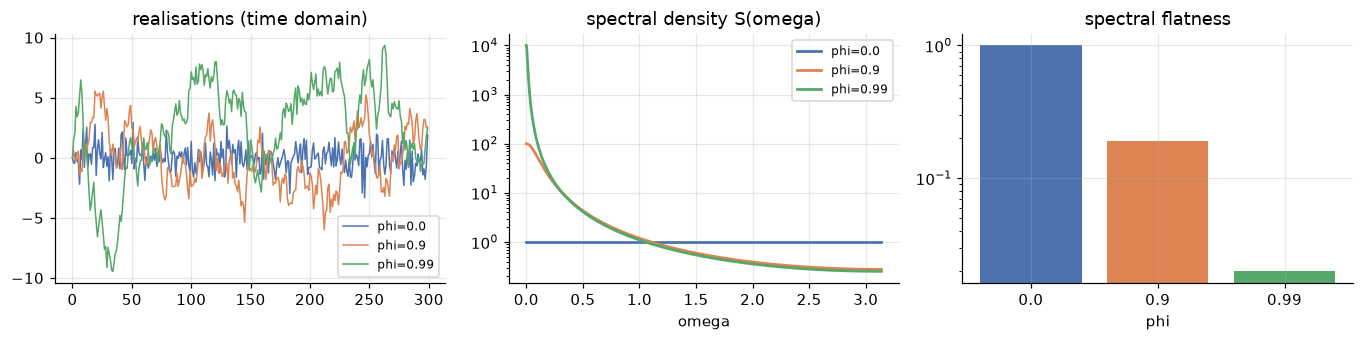

Flatness falls as phi rises: the same total power crowds into fewer frequencies.
Flatness = geometric mean / arithmetic mean of S = exp[2(h - h_white)] at fixed power.
For a Gaussian process, kernel <-> spectrum <-> entropy rate is one object viewed from three
sides, through the log-average. For a non-Gaussian process with the same covariance the rate is
lower, and the identity does not extend to a softmax attention matrix, which is not a
stationary positive-semidefinite covariance at all.


In [4]:
# The same statement as a picture: correlation in time = concentration in frequency = low entropy rate.
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.2))
n = 4000
for phi, c in ((0.0, "#4C72B0"), (0.9, "#DD8452"), (0.99, "#55A868")):
    e = rng.normal(0, 1, n); x = np.zeros(n)
    for t in range(1, n):
        x[t] = phi * x[t-1] + e[t]
    ax[0].plot(x[:300], lw=1, c=c, label=f"phi={phi}")
    w = 2*np.pi*np.arange(2048)/2048
    S = 1.0/np.abs(1-phi*np.exp(-1j*w))**2
    ax[1].semilogy(w[:1024], S[:1024], lw=1.8, c=c, label=f"phi={phi}")
    flat = np.exp(np.mean(np.log(S)))/np.mean(S)
    ax[2].bar(str(phi), flat, color=c)
ax[0].set_title("realisations (time domain)"); ax[0].legend(fontsize=8)
ax[1].set_title("spectral density S(omega)"); ax[1].set_xlabel("omega"); ax[1].legend(fontsize=8)
ax[2].set_title("spectral flatness"); ax[2].set_yscale("log"); ax[2].set_xlabel("phi")
plt.show()

print("Flatness falls as phi rises: the same total power crowds into fewer frequencies.")
print("Flatness = geometric mean / arithmetic mean of S = exp[2(h - h_white)] at fixed power.")
print("For a Gaussian process, kernel <-> spectrum <-> entropy rate is one object viewed from three")
print("sides, through the log-average. For a non-Gaussian process with the same covariance the rate is")
print("lower, and the identity does not extend to a softmax attention matrix, which is not a")
print("stationary positive-semidefinite covariance at all.")

---
## 2. Where a diffusion model's information actually lives

[W29](https://artifocial.com/blog/probabilistic-3d-reconstruction-2026-jul-16) built diffusion for 3D
reconstruction. The training objective there is the ELBO, which for a Gaussian diffusion decomposes
into a **sum of KL divergences, one per noise level**:

$$-\log p(x) \;\le\; \underbrace{D_{\mathrm{KL}}(q(x_T|x_0)\,\|\,p(x_T))}_{\text{prior term}} \;+\; \sum_{t} \underbrace{D_{\mathrm{KL}}\big(q(x_{t-1}|x_t,x_0)\,\|\,p_\theta(x_{t-1}|x_t)\big)}_{\text{one per step}} \;+\; \text{reconstruction}.$$

With base-2 logs and the appropriate expectations, these terms are measured in bits. So "how hard is step $t$?" has a numeric answer, and the **noise schedule** is the
thing that decides how the total is distributed across steps. That is a design decision usually
described in the language of stability and sample quality; here it is visible as an allocation of
information.

Below we compute forward-channel mutual information for a unit-variance Gaussian source, not the learned reverse-model KL decomposition above. Forward information drops describe signal retention; they do not measure training gradients or reverse-model errors.

In [5]:
def schedule(kind, T):
    """Returns alpha_bar[t], the retained signal fraction, t = 1..T."""
    t = np.arange(1, T + 1) / T
    if kind == "linear":
        betas = np.linspace(1e-4, 0.02, T)
        return np.cumprod(1 - betas)
    if kind == "cosine":                       # Nichol & Dhariwal style
        s = 0.008
        f = np.cos((t + s) / (1 + s) * np.pi / 2)**2
        return f / np.cos(np.array(s / (1 + s) * np.pi / 2))**2
    raise ValueError(kind)

T = 1000
var0 = 1.0                                      # data variance

# The forward process is q(x_t|x_0) = N(sqrt(ab_t) x_0, (1-ab_t) I), which is exactly a
# Gaussian channel with signal-to-noise ratio SNR_t = ab_t / (1 - ab_t). For a Gaussian
# source the information the noisy sample still carries about the clean one is the
# channel capacity expression, in closed form:
#
#     I(x_0 ; x_t) = 0.5 * log(1 + var0 * SNR_t)
#
# so "information destroyed at step t" is the DROP in that quantity, and the whole
# summed drop is I(t=1)-I(t=T); different endpoints mean different total drops.
def mutual_info_curve(ab, var0=1.0):
    snr = ab / (1.0 - ab)
    return 0.5 * np.log(1.0 + var0 * snr) * BITS          # bits

print("Information the noisy sample still carries about the clean one, I(x_0; x_t)")
print(f"{'schedule':>9} {'I at t=1':>11} {'I at t=T':>10} {'total destroyed':>16} {'SNR=1 at step':>15}")
store = {}
for kind in ("linear", "cosine"):
    ab = schedule(kind, T)
    I = mutual_info_curve(ab, var0)
    drops = -np.diff(I)                                   # bits destroyed by each step
    snr = ab / (1 - ab)
    cross = int(np.argmin(np.abs(np.log(snr)))) + 1        # where SNR passes through 1
    store[kind] = (ab, I, drops, snr)
    print(f"{kind:>9} {I[0]:>11.4f} {I[-1]:>10.4f} {drops.sum():>16.4f} {cross:>12} /{T}")
print()
print("I(x_0; x_t) starts high (the sample is nearly clean) and ends at essentially zero")
print("The schedule sets both the endpoints and the shape; these schedules have different totals.")

Information the noisy sample still carries about the clean one, I(x_0; x_t)
 schedule    I at t=1   I at t=T  total destroyed   SNR=1 at step
   linear      6.6439     0.0000           6.6438          259 /1000
   cosine      7.2820     0.0000           7.2820          496 /1000

I(x_0; x_t) starts high (the sample is nearly clean) and ends at essentially zero
The schedule sets both the endpoints and the shape; these schedules have different totals.


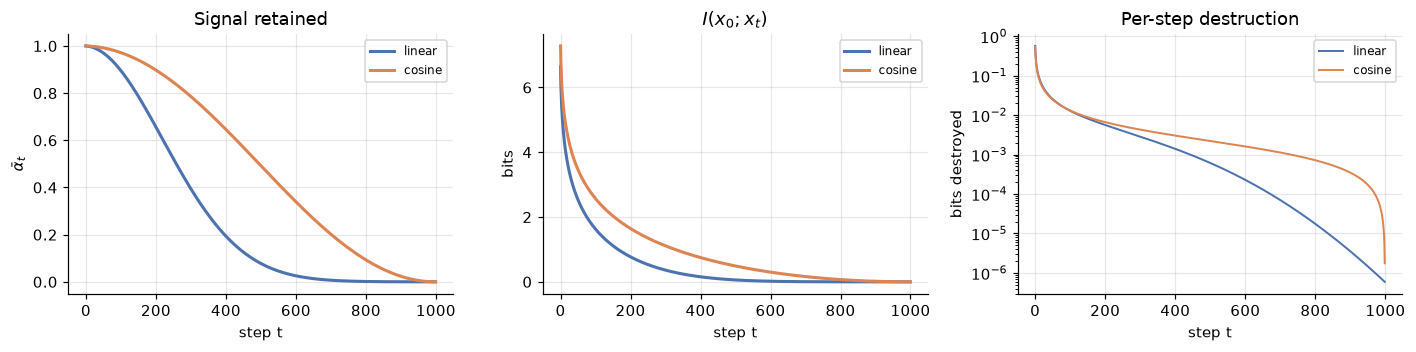

 schedule  median step of destruction   steps holding the middle 50%
   linear                       27 /1000            6-98  (9% of steps)
   cosine                       44 /1000          8-176  (17% of steps)

The middle half of all information destruction occupies 92 steps under the linear
schedule and 168 under the cosine one — a factor of 1.8 more steps
spanning the middle half of each schedule's own forward-information drop.

Forward mutual-information drops are not learned reverse-process KL terms or gradients.
Their totals differ because the starting signal fractions differ. Loss weighting,
timestep sampling, data and the model also determine the training signal.


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for kind, c in (("linear", "#4C72B0"), ("cosine", "#DD8452")):
    ab, I, drops, snr = store[kind]
    ax[0].plot(ab, lw=2, c=c, label=kind)
    ax[1].plot(I, lw=2, c=c, label=kind)
    ax[2].semilogy(np.maximum(drops, 1e-12), lw=1.3, c=c, label=kind)
ax[0].set_xlabel("step t"); ax[0].set_ylabel(r"$\bar{\alpha}_t$"); ax[0].set_title("Signal retained")
ax[1].set_xlabel("step t"); ax[1].set_ylabel("bits"); ax[1].set_title(r"$I(x_0; x_t)$")
ax[2].set_xlabel("step t"); ax[2].set_ylabel("bits destroyed"); ax[2].set_title("Per-step destruction")
for a in ax: a.legend(fontsize=8)
plt.show()

print(f"{'schedule':>9} {'median step of destruction':>27} {'steps holding the middle 50%':>30}")
for kind in ("linear", "cosine"):
    ab, I, drops, snr = store[kind]
    c = np.cumsum(drops) / drops.sum()
    q25 = int(np.searchsorted(c, 0.25)) + 1
    q50 = int(np.searchsorted(c, 0.50)) + 1
    q75 = int(np.searchsorted(c, 0.75)) + 1
    print(f"{kind:>9} {q50:>24} /{T} {f'{q25}-{q75}  ({(q75-q25)/T:.0%} of steps)':>30}")
print()
lin_q = store["linear"][2]; cos_q = store["cosine"][2]
lin_c = np.cumsum(lin_q)/lin_q.sum(); cos_c = np.cumsum(cos_q)/cos_q.sum()
lin_iqr = int(np.searchsorted(lin_c, .75)) - int(np.searchsorted(lin_c, .25))
cos_iqr = int(np.searchsorted(cos_c, .75)) - int(np.searchsorted(cos_c, .25))
print(f"The middle half of all information destruction occupies {lin_iqr} steps under the linear")
print(f"schedule and {cos_iqr} under the cosine one — a factor of {cos_iqr/lin_iqr:.1f} more steps")
print("spanning the middle half of each schedule's own forward-information drop.")
print()
print("Forward mutual-information drops are not learned reverse-process KL terms or gradients.")
print("Their totals differ because the starting signal fractions differ. Loss weighting,")
print("timestep sampling, data and the model also determine the training signal.")

### 2.1 I-MMSE, and why the diagnostic has to be an integral on both sides

For *any* finite-variance source observed through additive Gaussian noise at signal-to-noise ratio $s$,
the I-MMSE relation of Guo, Shamai & Verdú (2005) says $\tfrac{d}{ds} I(x_0; z_s) = \tfrac12\,\mathrm{mmse}(s)$
in nats. So the information destroyed on an SNR interval is an integral,
$\Delta I_i = \tfrac12\int_{s_i}^{s_{i+1}} \mathrm{mmse}(s)\,ds$, and the continuous-time diffusion loss
on the same interval is the matching integral of the *model's* MSE, $\tfrac12\int \mathbb E\|x_0 - \hat x_\theta(z_s, s)\|^2\,ds$.
The model's excess over the floor is the difference of the two integrals, and it is non-negative because
the MSE is at least the MMSE at every $s$. A one-point approximation of the model side — the MSE at one
SNR times the width of the step — cannot be read as model error: the cell below scores a **perfect**
denoiser that way and finds it either above or below its own floor depending on which endpoint is used.

One SNR interval, [1, 2], scored with a PERFECT denoiser (MSE = mmse at every s):
  exact information change   0.5*ln(3/2)                  = 0.2027 nats
  one-point rule, lower end  0.5*(2-1)*mmse(1) = 1/4      = 0.2500 nats   (+0.0473 vs exact)
  one-point rule, upper end  0.5*(2-1)*mmse(2) = 1/6      = 0.1667 nats   (-0.0361 vs exact)
  trapezoid                  0.25*(2-1)*(1/2 + 1/3)       = 0.2083 nats   (+0.0056 vs exact)
  The perfect denoiser sits 0.047 nats ABOVE its floor under one endpoint and 0.036 BELOW it under the
  other. That is quadrature, not model error. Integrate both sides with the same rule, or neither.

Across each schedule's own 999 steps, oracle denoiser, nats:
 schedule  exact total  lower-end rule  upper-end rule  trapezoid  max |one-step err|
   linear       4.6052          5.0700          4.2680     4.6690              0.2055
   cosine       5.0475          5.4542          4.7478     5.1010              0.1837

The exact totals are the 'total destroyed' c

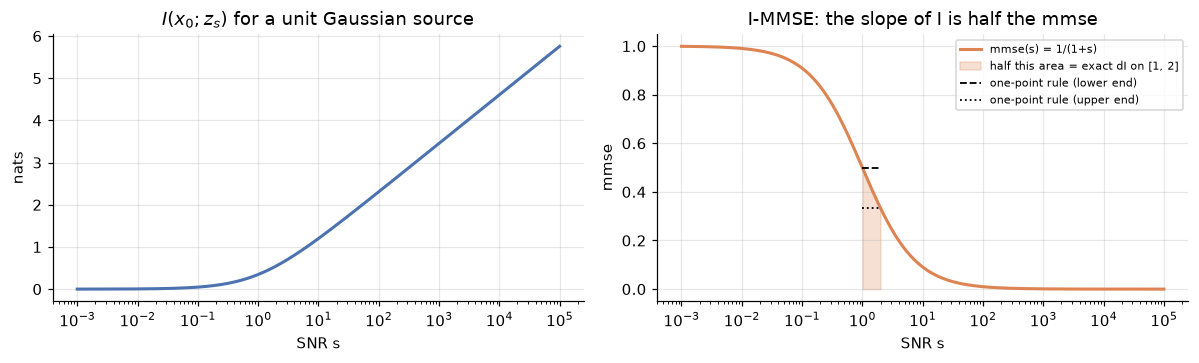

In [7]:
# Unit-variance Gaussian source in d = 1: mmse(s) = 1/(1+s) and I(x0; z_s) = 0.5 ln(1+s) nats, so the
# oracle denoiser is known in closed form and the quadrature error can be isolated from model error.
mmse = lambda s: 1.0 / (1.0 + s)
dI_exact = lambda lo, hi: 0.5 * np.log((1.0 + hi) / (1.0 + lo))      # 0.5 * integral of mmse over [lo, hi], nats

lo, hi = 1.0, 2.0
left  = 0.5 * (hi - lo) * mmse(lo)                 # MSE evaluated at the LOWER SNR end of the interval
right = 0.5 * (hi - lo) * mmse(hi)                 # ... at the HIGHER SNR end
trap  = 0.25 * (hi - lo) * (mmse(lo) + mmse(hi))
ex = dI_exact(lo, hi)
print("One SNR interval, [1, 2], scored with a PERFECT denoiser (MSE = mmse at every s):")
print(f"  exact information change   0.5*ln(3/2)                  = {ex:.4f} nats")
print(f"  one-point rule, lower end  0.5*(2-1)*mmse(1) = 1/4      = {left:.4f} nats   ({left-ex:+.4f} vs exact)")
print(f"  one-point rule, upper end  0.5*(2-1)*mmse(2) = 1/6      = {right:.4f} nats   ({right-ex:+.4f} vs exact)")
print(f"  trapezoid                  0.25*(2-1)*(1/2 + 1/3)       = {trap:.4f} nats   ({trap-ex:+.4f} vs exact)")
print("  The perfect denoiser sits 0.047 nats ABOVE its floor under one endpoint and 0.036 BELOW it under the")
print("  other. That is quadrature, not model error. Integrate both sides with the same rule, or neither.")
print()
print("Across each schedule's own 999 steps, oracle denoiser, nats:")
print(f"{'schedule':>9} {'exact total':>12} {'lower-end rule':>15} {'upper-end rule':>15} {'trapezoid':>10} {'max |one-step err|':>19}")
for kind in ("linear", "cosine"):
    ab, I, drops, snr = store[kind]
    s_hi, s_lo = snr[:-1], snr[1:]                                   # SNR falls as t increases
    ex_steps = dI_exact(s_lo, s_hi)
    lower = 0.5 * (s_hi - s_lo) * mmse(s_lo)
    upper = 0.5 * (s_hi - s_lo) * mmse(s_hi)
    trapz = 0.25 * (s_hi - s_lo) * (mmse(s_lo) + mmse(s_hi))
    print(f"{kind:>9} {ex_steps.sum():>12.4f} {lower.sum():>15.4f} {upper.sum():>15.4f} {trapz.sum():>10.4f} {np.abs(lower-ex_steps).max():>19.4f}")
print()
print("The exact totals are the 'total destroyed' column above, in nats (6.6438 and 7.2820 bits x ln 2).")
print("A perfect denoiser scored by a one-point rule lands away from its own floor, and the one-step error is")
print("largest where a step is wide in SNR — at the clean end of each schedule, where SNR changes fastest.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
s = np.logspace(-3, 5, 600)
ax[0].semilogx(s, 0.5 * np.log(1 + s), lw=2, c="#4C72B0")
ax[0].set_xlabel("SNR s"); ax[0].set_ylabel("nats"); ax[0].set_title(r"$I(x_0; z_s)$ for a unit Gaussian source")
m = (s >= lo) & (s <= hi)
ax[1].semilogx(s, mmse(s), lw=2, c="#DD8452", label="mmse(s) = 1/(1+s)")
ax[1].fill_between(s[m], 0, mmse(s[m]), color="#DD8452", alpha=0.25, label="half this area = exact dI on [1, 2]")
ax[1].hlines(mmse(lo), lo, hi, colors="k", linestyles="--", lw=1.2, label="one-point rule (lower end)")
ax[1].hlines(mmse(hi), lo, hi, colors="k", linestyles=":", lw=1.2, label="one-point rule (upper end)")
ax[1].set_xlabel("SNR s"); ax[1].set_ylabel("mmse"); ax[1].set_title("I-MMSE: the slope of I is half the mmse"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

---
## 3. Equal ELBO scores need not imply equal representations

The VAE objective is usually written as "reconstruction + KL". **Fixing a Broken ELBO**
([arXiv:1711.00464](https://arxiv.org/abs/1711.00464)) makes the better decomposition explicit:

$$-\mathrm{ELBO} \;=\; \underbrace{\mathbb{E}\,D_{\mathrm{KL}}(q(z|x)\|p(z))}_{\textbf{rate } R} \;+\; \underbrace{\mathbb{E}\left[-\log p(x|z)\right]}_{\textbf{distortion } D}$$

With base-2 logs, $R=I_q(X;Z)+D_{\mathrm{KL}}(q(z)\Vert p(z))$: rate bounds latent information and also includes prior mismatch. Distortion is expected negative log conditional density, which can be negative for continuous data. Equal $R+D$ means equal score, not equal optimality or a zero gradient.

The fixed linear-Gaussian decoder below admits an exact posterior at $a=10/11$, $s^2=1/11$. That encoder minimizes the negative ELBO. The sampled level set excludes zero rate and does not demonstrate posterior collapse. We also search $D+\beta R$ to illustrate how changing the rate price changes the optimum within this family.

Three encoders, to show what the two terms mean:
                     encoder  rate R [bits]  distortion D [bits]   -ELBO = R+D
       collapsed (a=0, s2=1)         0.0000              14.8131       14.8131
    balanced (a=0.6, s2=0.3)         0.6492               3.0984        3.7476
 high-rate (a=0.95, s2=0.05)         2.1918               0.0453        2.2371

These three have DIFFERENT ELBOs, so they are not yet the degeneracy — they are just
the vocabulary. The degeneracy is what happens along a LEVEL SET of R+D, below.

Encoders whose -ELBO equals 2.3131 bits to within 0.002:
  count                : 725
  rate R spans         : 1.2578 to 2.3398 bits  (a spread of 1.0820 bits)
  distortion D spans   : -0.0251 to 1.0571 bits

Near-equal scores within the stated tolerance. The rate spans
1.26 to 2.34 bits. This band contains no zero-rate encoder.
It is not a set of minima and does not demonstrate posterior collapse.
Exact-posterior minimum: R=1.729716, D=0.386132, -ELBO=2.115847 bi

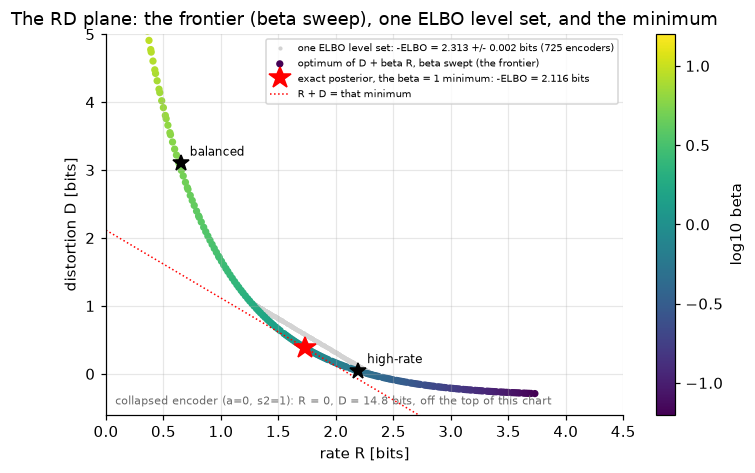

beta=15.85 lands at R=0.191 bits  (latent nearly unused)
beta=0.06 lands at R=3.731 bits  (latent carrying real information)
Same model family, same data, same ELBO machinery. Only the price of a bit changed.


In [8]:
# Linear-Gaussian model: x = z + noise, z ~ N(0,1), q(z|x) = N(a*x, s2).
# Both R and D are available in closed form, so the (R, D) plane is exact.
sigma_x2 = 0.1                       # observation noise variance

def rate_distortion_point(a, s2):
    var_x = 1.0 + sigma_x2
    R = 0.5 * (np.log(1.0 / s2) + (s2 + a**2 * var_x) - 1.0) * BITS
    D = 0.5 * (np.log(2 * np.pi * sigma_x2) + ((1 - a)**2 * var_x + s2) / sigma_x2) * BITS
    return R, D

print("Three encoders, to show what the two terms mean:")
print(f"{'encoder':>28} {'rate R [bits]':>14} {'distortion D [bits]':>20} {'-ELBO = R+D':>13}")
cases = [("collapsed (a=0, s2=1)", 0.0, 1.0),
         ("balanced (a=0.6, s2=0.3)", 0.6, 0.3),
         ("high-rate (a=0.95, s2=0.05)", 0.95, 0.05)]
for name, a, s2 in cases:
    R, D = rate_distortion_point(a, s2)
    print(f"{name:>28} {R:>14.4f} {D:>20.4f} {R+D:>13.4f}")
print()
print("These three have DIFFERENT ELBOs, so they are not yet the degeneracy — they are just")
print("the vocabulary. The degeneracy is what happens along a LEVEL SET of R+D, below.")
print()

# The degeneracy, measured: encoders the ELBO cannot tell apart.
grid_a = np.linspace(0, 1, 1200); grid_s = np.logspace(-3, 0.3, 900)
A, S = np.meshgrid(grid_a, grid_s, indexing="ij")
Rg, Dg = rate_distortion_point(A, S)
E = Rg + Dg
target = np.percentile(E, 4)                  # a representative achievable ELBO level
band = np.abs(E - target) < 0.002             # encoders whose ELBO agrees to 0.002 bits
Rb, Db_ = Rg[band], Dg[band]
print(f"Encoders whose -ELBO equals {target:.4f} bits to within 0.002:")
print(f"  count                : {band.sum():,}")
print(f"  rate R spans         : {Rb.min():.4f} to {Rb.max():.4f} bits  "
      f"(a spread of {Rb.max()-Rb.min():.4f} bits)")
print(f"  distortion D spans   : {Db_.min():.4f} to {Db_.max():.4f} bits")
print()
print("Near-equal scores within the stated tolerance. The rate spans")
print(f"{Rb.min():.2f} to {Rb.max():.2f} bits. This band contains no zero-rate encoder.")
print("It is not a set of minima and does not demonstrate posterior collapse.")
Ropt, Dopt = rate_distortion_point(10/11, 1/11)
print(f"Exact-posterior minimum: R={Ropt:.6f}, D={Dopt:.6f}, -ELBO={Ropt+Dopt:.6f} bits")
assert Ropt+Dopt < target-0.002
print()

# Sweep beta and trace the achievable frontier.
betas = np.logspace(-1.2, 1.2, 200)
pts = []
for beta in betas:
    grid_a = np.linspace(0, 1, 400); grid_s = np.logspace(-3, 0, 300)
    A, S = np.meshgrid(grid_a, grid_s, indexing="ij")
    R, D = rate_distortion_point(A, S)
    obj = beta * R + D
    i = np.unravel_index(np.argmin(obj), obj.shape)
    pts.append((R[i], D[i], beta))
pts = np.array(pts)

fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.scatter(Rb, Db_, s=3, c="lightgrey", label=f"one ELBO level set: -ELBO = {target:.3f} +/- 0.002 bits ({band.sum():,} encoders)")
sc = ax.scatter(pts[:, 0], pts[:, 1], c=np.log10(pts[:, 2]), cmap="viridis", s=14, label="optimum of D + beta R, beta swept (the frontier)")
plt.colorbar(sc, label="log10 beta")
ax.plot(Ropt, Dopt, "r*", ms=15, label=f"exact posterior, the beta = 1 minimum: -ELBO = {Ropt+Dopt:.3f} bits")
rr = np.linspace(0, 4.5, 60); ax.plot(rr, (Ropt + Dopt) - rr, "r:", lw=1, label="R + D = that minimum")
for name, a, s2 in cases:
    R, D = rate_distortion_point(a, s2)
    if D < 5:
        ax.plot(R, D, "k*", ms=11)
        ax.annotate(name.split(" (")[0], (R, D), textcoords="offset points", xytext=(6, 5), fontsize=8)
ax.text(0.08, -0.45, "collapsed encoder (a=0, s2=1): R = 0, D = 14.8 bits, off the top of this chart", fontsize=7, color="dimgrey")
ax.set_xlim(0, 4.5); ax.set_ylim(-0.6, 5.0)
ax.set_xlabel("rate R [bits]"); ax.set_ylabel("distortion D [bits]")
ax.set_title("The RD plane: the frontier (beta sweep), one ELBO level set, and the minimum")
ax.legend(fontsize=6.5, loc="upper right")
plt.tight_layout(); plt.show()

lo, hi = pts[np.argmin(pts[:, 2])], pts[np.argmax(pts[:, 2])]
print(f"beta={hi[2]:.2f} lands at R={hi[0]:.3f} bits  (latent nearly unused)")
print(f"beta={lo[2]:.2f} lands at R={lo[0]:.3f} bits  (latent carrying real information)")
print("Same model family, same data, same ELBO machinery. Only the price of a bit changed.")

---
## 4. How close does a real codec get to the bound?

[W14](https://artifocial.com/blog/gaussian-splatting-explained-2026-apr-03) asked how many Gaussians
a scene needs — a rate–distortion question in disguise. Here we ask the clean version of it, on a
correlated Gaussian source where the bound is known exactly.

For a Gaussian vector source with covariance eigenvalues $\lambda_i$ under squared-error distortion,
the rate–distortion function is given by **reverse water-filling**: pick a water level $\theta$,
spend no bits on components with $\lambda_i < \theta$ (just send zero), and spend
$\tfrac12\log_2(\lambda_i/\theta)$ bits on the rest. The threshold comes from the KKT conditions of
*this* problem — a separable convex objective whose marginal value $-1/(2D_i)$ is unbounded as
$D_i \to 0$, with a hard cap $D_i \le \lambda_i$ — and it is not what every budget allocation looks
like: a proportional-fairness allocation is interior, an entropy-regularised one is a softmax. Check
whether your constraint set is this one before reading a threshold into it.

Then we build the quantiser half of a codec — decorrelate with the KLT (which is PCA, which is what
the DCT approximates in JPEG) and quantise uniformly — and charge ourselves the **sum of the empirical
marginal entropies of the quantiser indices**, $R_{\text{est}} = \tfrac1d\sum_j H(\hat Z_j)$ bits per
sample. No bitstream is written. That number is the rate an ideal entropy coder of the per-coefficient
marginals approaches from above, with a finite-length overhead on top; it is an *estimated
entropy-coded rate*, not a measured file size, and the column is labelled accordingly. We then measure
its gap to the bound. At high resolution, theory predicts an **asymptotically fixed** gap of about
$\tfrac12\log_2\tfrac{\pi e}{6} \approx 0.254$ bits per sample, in the high-rate limit: the
space-filling loss of a scalar quantiser. Finite-rate gaps need not equal this limit, as the sweep below shows.

In [9]:
# A correlated Gaussian source: AR(1) covariance, the standard stand-in for image rows.
d, phi = 16, 0.9
idx = np.arange(d)
Sigma = phi ** np.abs(idx[:, None] - idx[None, :])
lam, U = np.linalg.eigh(Sigma)
lam = lam[::-1]; U = U[:, ::-1]

def rd_bound(theta):
    D = np.sum(np.minimum(lam, theta))
    R = np.sum(0.5 * np.log2(np.maximum(lam / theta, 1.0)))
    return R / d, D / d                                   # per sample

N = 200_000
Xs = rng.multivariate_normal(np.zeros(d), Sigma, size=N)
Z = Xs @ U                                                # KLT: decorrelate

def code_at_step(delta):
    """Uniform scalar quantiser on each KLT coefficient + empirical entropy."""
    q = np.round(Z / delta)
    Zhat = q * delta
    D = np.mean((Z - Zhat)**2)                            # KLT is orthonormal: MSE is preserved
    R = 0.0
    for j in range(d):
        vals, counts = np.unique(q[:, j], return_counts=True)
        p = counts / counts.sum()
        R += -np.sum(p * np.log2(p))
    return R / d, D

print(f"AR(1) Gaussian source, d={d}, phi={phi}, {N:,} samples")
print(f"{'step':>7} {'R est.':>9} {'D':>9} {'R bound at same D':>19} {'gap [bits/sample]':>18}")
print("        (R est. = sum of empirical marginal entropies of the quantiser indices; no entropy coder is run)")
gaps, rate_list = [], []
for delta in (2.0, 1.4, 1.0, 0.7, 0.5, 0.35, 0.25, 0.18, 0.12):
    Rc, Dc = code_at_step(delta)
    thetas = np.logspace(-6, 1, 20000)
    Ds = np.array([np.sum(np.minimum(lam, th)) / d for th in thetas])
    th = thetas[np.argmin(np.abs(Ds - Dc))]
    Rb, _ = rd_bound(th)
    gaps.append(Rc - Rb); rate_list.append(Rc)
    print(f"{delta:>7.2f} {Rc:>9.4f} {Dc:>9.5f} {Rb:>19.4f} {Rc-Rb:>18.4f}")

pred = 0.5 * np.log2(np.pi * np.e / 6)
gaps = np.array(gaps)
rates = np.array(rate_list)
print(f"\ntheoretical space-filling gap (high-resolution limit) = {pred:.4f} bits/sample")
print(f"measured gap: min {gaps.min():.4f}, max {gaps.max():.4f}, mean {gaps.mean():.4f}")
print()
print("The prediction is an ASYMPTOTIC one, so test it where it applies — at high rate:")
hi = rates >= 2.5
print(f"  rates >= 2.5 bits/sample: mean gap = {gaps[hi].mean():.4f}, spread {gaps[hi].std():.4f} over the {int(hi.sum())} operating points "
      f"(predicted {pred:.4f})")
print("    — the spread is variation across step sizes, not a confidence interval; the block repeat below is the uncertainty")
print(f"  rates <  1.5 bits/sample: gap = {gaps[~hi & (rates<1.5)].mean():.4f}  "
      f"— the high-resolution approximation does not hold here")
print()
print(f"At the highest rate measured the gap is {gaps[-1]:.4f} against a prediction of {pred:.4f},")
print(f"an error of {abs(gaps[-1]-pred):.4f} bits, and it is still converging downward.")
print()
# An empirical uncertainty for ONE operating point: the same quantiser at the finest step on five disjoint
# 40,000-sample blocks of the same data. This is repetition over data, which a spread across step sizes is not.
Ds_grid = np.array([np.sum(np.minimum(lam, th)) / d for th in thetas])
blk = []
for b in range(5):
    Zb = Z[b * 40_000:(b + 1) * 40_000]
    qb = np.round(Zb / 0.12); Db = np.mean((Zb - qb * 0.12) ** 2)
    Rb_est = 0.0
    for j in range(d):
        _, cnt = np.unique(qb[:, j], return_counts=True); pj = cnt / cnt.sum()
        Rb_est += -np.sum(pj * np.log2(pj))
    Rb_est /= d
    Rb_bound, _ = rd_bound(thetas[np.argmin(np.abs(Ds_grid - Db))])
    blk.append(Rb_est - Rb_bound)
blk = np.array(blk)
print(f"Block repeat at step 0.12 (five disjoint 40,000-sample blocks): gap = {blk.mean():.4f} +/- {blk.std(ddof=1):.4f} bits/sample")
print(f"  (mean +/- SD ACROSS the five 40,000-sample block estimates — an across-block dispersion, not a confidence")
print(f"   interval for the 200,000-sample value {gaps[-1]:.4f}; per block {', '.join(f'{g:.4f}' for g in blk)};")
print("   a 40,000-sample plug-in entropy reads slightly low, which is the direction of the small difference)")
print("So the honest reading is: the quarter-bit space-filling loss is real and shows up where")
print("theory says it should, and the low-rate points are NOT evidence against it — they are")
print("outside the regime the formula describes. Reporting the mean over all rates would have")
print("hidden both facts inside one number that matches nothing.")
print()
print("A scalar quantiser loses that quarter bit per sample to the shape of its cells, and no")
print("amount of engineering inside that design removes it — you have to change the design")
print("(vector quantisation, lattices, or a learned entropy model) to get it back.")

AR(1) Gaussian source, d=16, phi=0.9, 200,000 samples
   step    R est.         D   R bound at same D  gap [bits/sample]
        (R est. = sum of empirical marginal entropies of the quantiser indices; no entropy coder is run)


   2.00    0.4889   0.16359              0.3506             0.1384


   1.40    0.7483   0.10814              0.5387             0.2097


   1.00    1.1185   0.06934              0.8069             0.3116


   0.70    1.5950   0.03908              1.2157             0.3792


...

   0.35    2.5009   0.01020              2.1843             0.3166


   0.25    2.9572   0.00521              2.6692             0.2880


   0.18    3.4155   0.00270              3.1430             0.2725


   0.12    3.9909   0.00120              3.7278             0.2631

theoretical space-filling gap (high-resolution limit) = 0.2546 bits/sample
measured gap: min 0.1384, max 0.3792, mean 0.2826

The prediction is an ASYMPTOTIC one, so test it where it applies — at high rate:
  rates >= 2.5 bits/sample: mean gap = 0.2850, spread 0.0203 over the 4 operating points (predicted 0.2546)
    — the spread is variation across step sizes, not a confidence interval; the block repeat below is the uncertainty
  rates <  1.5 bits/sample: gap = 0.2199  — the high-resolution approximation does not hold here

At the highest rate measured the gap is 0.2631 against a prediction of 0.2546,
an error of 0.0084 bits, and it is still converging downward.



Block repeat at step 0.12 (five disjoint 40,000-sample blocks): gap = 0.2621 +/- 0.0011 bits/sample
  (mean +/- SD ACROSS the five 40,000-sample block estimates — an across-block dispersion, not a confidence
   interval for the 200,000-sample value 0.2631; per block 0.2615, 0.2639, 0.2619, 0.2623, 0.2609;
   a 40,000-sample plug-in entropy reads slightly low, which is the direction of the small difference)
So the honest reading is: the quarter-bit space-filling loss is real and shows up where
theory says it should, and the low-rate points are NOT evidence against it — they are
outside the regime the formula describes. Reporting the mean over all rates would have
hidden both facts inside one number that matches nothing.

A scalar quantiser loses that quarter bit per sample to the shape of its cells, and no
amount of engineering inside that design removes it — you have to change the design
(vector quantisation, lattices, or a learned entropy model) to get it back.


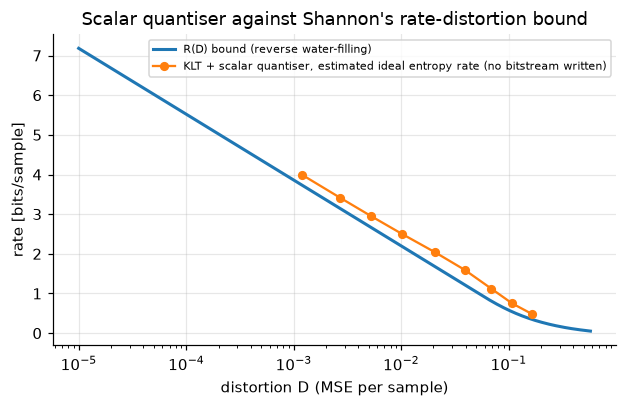

Eigenvalue spectrum of the source (the 'which components deserve bits' ranking):
  9.927  2.949  1.128  0.568  0.341  0.229  0.167  0.129  ...
  top 4 of 16 components hold 91.1% of the variance —
  which is the entire reason transform coding works. The W14 question 'how many Gaussians?'
  RESEMBLES 'where do you put the water level?' — a splat count is a model-complexity budget,
  and it becomes a rate only once a representation and an entropy code for the splats are fixed.


In [10]:
thetas = np.logspace(-5, 0.5, 400)
curve = np.array([rd_bound(t) for t in thetas])
fig, ax = plt.subplots(figsize=(5.8, 3.8))
ax.plot(curve[:, 1], curve[:, 0], lw=2, label="R(D) bound (reverse water-filling)")
pts = []
for delta in (2.0, 1.4, 1.0, 0.7, 0.5, 0.35, 0.25, 0.18, 0.12):
    Rc, Dc = code_at_step(delta); pts.append((Dc, Rc))
pts = np.array(pts)
ax.plot(pts[:, 0], pts[:, 1], "o-", ms=5, label="KLT + scalar quantiser, estimated ideal entropy rate (no bitstream written)")
ax.set_xscale("log"); ax.set_xlabel("distortion D (MSE per sample)"); ax.set_ylabel("rate [bits/sample]")
ax.set_title("Scalar quantiser against Shannon's rate-distortion bound"); ax.legend(fontsize=7)
plt.show()

print(f"Eigenvalue spectrum of the source (the 'which components deserve bits' ranking):")
print("  " + "  ".join(f"{v:.3f}" for v in lam[:8]) + "  ...")
print(f"  top 4 of {d} components hold {lam[:4].sum()/lam.sum():.1%} of the variance —")
print("  which is the entire reason transform coding works. The W14 question 'how many Gaussians?'")
print("  RESEMBLES 'where do you put the water level?' — a splat count is a model-complexity budget,")
print("  and it becomes a rate only once a representation and an entropy code for the splats are fixed.")

---
## 5. A verification-noise threshold in self-improvement

> **Scope, restated because it matters.** What follows is a **toy model we built**, not a
> reproduction of any paper's theorem. [arXiv:2512.02731](https://arxiv.org/abs/2512.02731) proves a
> spectral stability condition for a capability functional under a Generator–Verifier–Updater
> operator, and states its sufficient condition in terms of the **combined noise** of generation and
> verification being small enough. It does not state a law about entropy production, and the phrase
> "Second Law of AGI Dynamics" is not its language. The thermodynamic reading below is **our
> analogy**, offered as intuition and labelled as such.

The structural question is real regardless of the framing: a system that generates candidates,
verifies them, and trains on what passes is a feedback loop, and feedback loops have stability
conditions. We build the simplest version that can exhibit one.

A "skill" is a scalar $\theta$ with a true optimum at $\theta^\star$. Each round the generator
proposes $K$ candidates around its current belief; a verifier scores them with **noise** $\sigma_v$;
the updater moves toward the best-scoring candidate. We sweep $\sigma_v$ under two exploration
policies — one that keeps searching at a fixed scale, one that narrows its search as it goes — and
measure both the capability reached and how reproducible it is across seeds.

The second policy is there because the first version of this experiment only had one, and which one
you pick turns out to change the answer completely.

In [11]:
def self_play(sigma_v, rounds=400, K=16, sigma_g=0.35, lr=0.5, seed=0, anneal=1.0):
    """
    Generator proposes K candidates, a noisy verifier scores them, the updater moves
    toward the best-scoring one.

    anneal = 1.0  : exploration scale stays fixed  ("keep searching")
    anneal < 1.0  : exploration scale decays each round ("narrow down as you gain
                    confidence") — the standard, sensible-looking engineering choice.
    """
    r = np.random.default_rng(seed)
    theta, s = 0.0, sigma_g
    for t in range(rounds):
        cand = theta + r.normal(0, s, K)
        true_score = -(cand - 1.0)**2                       # optimum at theta* = 1
        obs = true_score + r.normal(0, sigma_v, K)          # the verifier is noisy
        best = cand[np.argmax(obs)]
        theta = theta + lr * (best - theta)
        s *= anneal
    return theta

REPS = 48
SVS = (0.0, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0)

print("Generator-Verifier-Updater loop, optimum at theta* = 1.0, 48 seeds per setting")
print()
print(f"{'':>15} {'--- exploration FIXED ---':>27} {'--- exploration ANNEALED ---':>30}")
print(f"{'verifier noise':>15} {'mean theta':>12} {'spread':>14} {'mean theta':>16} {'spread':>13}")
res_fixed, res_anneal = {}, {}
for sv in SVS:
    f = np.array([self_play(sv, seed=s, anneal=1.0) for s in range(REPS)])
    a = np.array([self_play(sv, seed=s, anneal=0.985) for s in range(REPS)])
    res_fixed[sv] = (f.mean(), f.std()); res_anneal[sv] = (a.mean(), a.std())
    print(f"{sv:>15.2f} {f.mean():>12.4f} {f.std():>14.4f} {a.mean():>16.4f} {a.std():>13.4f}")
print()
print("Read the two 'mean theta' columns against each other. They are the same loop with the")
print("same verifier; only the exploration policy differs. 'spread' is np.std (ddof=0) over the 48 seeds.")

Generator-Verifier-Updater loop, optimum at theta* = 1.0, 48 seeds per setting

                  --- exploration FIXED ---   --- exploration ANNEALED ---
 verifier noise   mean theta         spread       mean theta        spread


           0.00       0.9991         0.0233           1.0000        0.0001


           0.05       0.9966         0.0694           0.9986        0.0583


           0.10       0.9903         0.0861           1.0003        0.0853


           0.25       0.9841         0.1412           1.0213        0.1314


           0.50       0.9688         0.2108           1.0355        0.1987


           1.00       0.9597         0.2609           1.0718        0.3116


           2.00       0.9543         0.3652           1.1119        0.4735


           4.00       0.9446         0.4716           1.0318        0.6247


           8.00       0.9347         0.6228           0.8788        0.7998

Read the two 'mean theta' columns against each other. They are the same loop with the
same verifier; only the exploration policy differs. 'spread' is np.std (ddof=0) over the 48 seeds.


In [12]:
# Mean theta is NOT mean capability. The task loss is L(theta) = (theta - 1)^2, and
#     E[L(theta)] = Var(theta) + (E[theta] - 1)^2,
# so the mean regret of each setting follows EXACTLY from the two printed columns above.
print("Mean regret E[L(theta)] = var + bias^2, from the printed mean/spread columns (48 seeds per setting)")
print(f"{'verifier noise':>15} | {'fixed: E[L]':>12} {'= var':>9} {'+ bias^2':>9} | {'annealed: E[L]':>15} {'= var':>9} {'+ bias^2':>9} | {'annealed/fixed':>14}")
for sv in SVS:
    (mf, sf), (ma, sa) = res_fixed[sv], res_anneal[sv]
    Lf, La = sf**2 + (mf - 1.0)**2, sa**2 + (ma - 1.0)**2
    print(f"{sv:>15.2f} | {Lf:>12.5f} {sf**2:>9.5f} {(mf-1)**2:>9.5f} | {La:>15.5f} {sa**2:>9.5f} {(ma-1)**2:>9.5f} | {La/max(Lf,1e-12):>13.2f}x")
mf, sf = res_fixed[8.0]; ma, sa = res_anneal[8.0]
Lf8, La8 = sf**2 + (mf-1)**2, sa**2 + (ma-1)**2
print()
print(f"At sigma_v = 8: fixed exploration {Lf8:.3f}, annealed {La8:.3f}; holding exploration open cuts the mean")
print(f"regret by {100*(1-Lf8/La8):.0f}% (annealing costs {100*(La8/Lf8-1):.0f}% more). Almost all of either number is VARIANCE —")
print("seeds scattered around an optimum the average still finds — and the squared-bias share is small and")
print("not monotone in the noise. Report the mean task loss, never the mean parameter.")

Mean regret E[L(theta)] = var + bias^2, from the printed mean/spread columns (48 seeds per setting)
 verifier noise |  fixed: E[L]     = var  + bias^2 |  annealed: E[L]     = var  + bias^2 | annealed/fixed
           0.00 |      0.00055   0.00055   0.00000 |         0.00000   0.00000   0.00000 |          0.00x
           0.05 |      0.00482   0.00481   0.00001 |         0.00341   0.00340   0.00000 |          0.71x
           0.10 |      0.00752   0.00742   0.00009 |         0.00728   0.00728   0.00000 |          0.97x
           0.25 |      0.02020   0.01995   0.00025 |         0.01771   0.01725   0.00045 |          0.88x
           0.50 |      0.04542   0.04444   0.00098 |         0.04075   0.03949   0.00126 |          0.90x
           1.00 |      0.06969   0.06806   0.00163 |         0.10225   0.09709   0.00516 |          1.47x
           2.00 |      0.13550   0.13341   0.00209 |         0.23676   0.22422   0.01253 |          1.75x
           4.00 |      0.22544   0.22237   0.00307 |

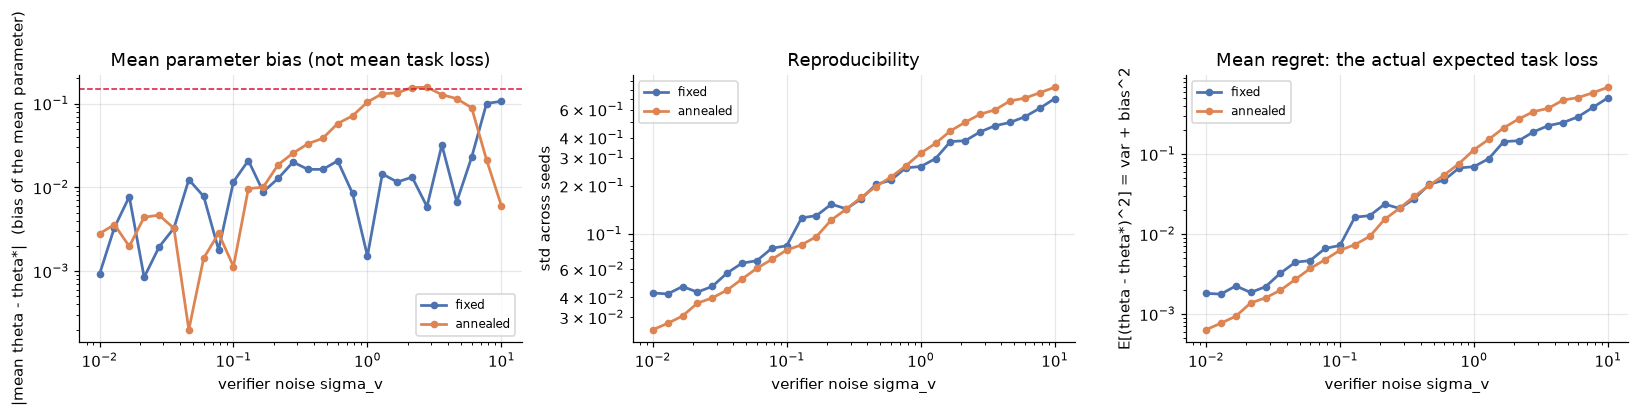

    fixed: mean error never crosses 0.15 (max 0.1066) — no threshold in this window
           dispersion 0.0425 -> 0.7028 over the sweep (17x)
 annealed: mean error crosses 0.15 at sigma_v = 2.154
           dispersion 0.0250 -> 0.8279 over the sweep (33x)

('dispersion' here is np.std over 32 seeds at the two ENDS of this 28-point log grid, sigma_v = 0.01
 and 10; the 'spread' column of the table above is np.std over 48 seeds at the listed levels, which
 is why the two ranges have different endpoints. Only 'spread' feeds the mean-regret table.)

Read the mean-regret table above, not the mean-theta columns. With exploration held open,
verifier noise DOES cost mean capability — at sigma_v = 8 the mean regret is some 700x the
noise-free value — and almost all of that cost is variance: seeds scattered around an optimum
that the average still finds. Anneal the exploration — the ordinary, sensible engineering
choice, narrowing the search as confidence grows — and the same noise costs about

In [13]:
svs = np.logspace(-2, 1.0, 28)
curves = {}
for tag, an in (("fixed", 1.0), ("annealed", 0.985)):
    e, d = [], []
    for sv in svs:
        f = np.array([self_play(sv, seed=s, anneal=an) for s in range(32)])
        e.append(abs(f.mean() - 1.0)); d.append(f.std())
    curves[tag] = (np.array(e), np.array(d))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for tag, c in (("fixed", "#4C72B0"), ("annealed", "#DD8452")):
    e, d = curves[tag]
    ax[0].loglog(svs, np.maximum(e, 1e-4), "o-", lw=1.8, c=c, ms=4, label=tag)
    ax[1].loglog(svs, np.maximum(d, 1e-4), "o-", lw=1.8, c=c, ms=4, label=tag)
    ax[2].loglog(svs, np.maximum(d**2 + e**2, 1e-6), "o-", lw=1.8, c=c, ms=4, label=tag)   # E[L] = var + bias^2, the actual expected regret
ax[0].axhline(0.15, ls="--", c="crimson", lw=1)
ax[0].set_xlabel("verifier noise sigma_v"); ax[0].set_ylabel("|mean theta - theta*|  (bias of the mean parameter)")
ax[0].set_title("Mean parameter bias (not mean task loss)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("verifier noise sigma_v"); ax[1].set_ylabel("std across seeds")
ax[1].set_title("Reproducibility"); ax[1].legend(fontsize=8)
ax[2].set_xlabel("verifier noise sigma_v"); ax[2].set_ylabel("E[(theta - theta*)^2] = var + bias^2")
ax[2].set_title("Mean regret: the actual expected task loss"); ax[2].legend(fontsize=8)
plt.show()

for tag in ("fixed", "annealed"):
    e, d = curves[tag]
    if e.max() > 0.15:
        thr = svs[int(np.argmax(e > 0.15))]
        print(f"{tag:>9}: mean error crosses 0.15 at sigma_v = {thr:.3f}")
    else:
        print(f"{tag:>9}: mean error never crosses 0.15 (max {e.max():.4f}) — no threshold in this window")
    print(f"{'':>9}  dispersion {d[0]:.4f} -> {d[-1]:.4f} over the sweep "
          f"({d[-1]/max(d[0],1e-9):.0f}x)")
print()
print("('dispersion' here is np.std over 32 seeds at the two ENDS of this 28-point log grid, sigma_v = 0.01")
print(" and 10; the 'spread' column of the table above is np.std over 48 seeds at the listed levels, which")
print(" is why the two ranges have different endpoints. Only 'spread' feeds the mean-regret table.)")
print()
print("Read the mean-regret table above, not the mean-theta columns. With exploration held open,")
print("verifier noise DOES cost mean capability — at sigma_v = 8 the mean regret is some 700x the")
print("noise-free value — and almost all of that cost is variance: seeds scattered around an optimum")
print("that the average still finds. Anneal the exploration — the ordinary, sensible engineering")
print("choice, narrowing the search as confidence grows — and the same noise costs about two thirds")
print("more, with a larger (still small) share of it as bias: the loop commits to whatever it believed")
print("while it was still being fooled, and then stops sampling widely enough to find out otherwise.")
print()
print("So 'signal must exceed noise' is a joint property of the verifier and the exploration policy,")
print("and open exploration is a hedge that cuts the regret by about 40% at high noise — not a policy")
print("that preserves capability. The honest monitoring consequence: report the mean task loss, never")
print("the mean parameter, and watch the spread across seeds, which is almost the whole of the regret.")
print()
print("What this does NOT establish: that real self-improving systems behave this way at any")
print("particular noise level, that our sigma_v corresponds to a measurable quantity in a real")
print("verifier, or that the referenced paper's Variance Inequality says this. It says a toy")
print("loop with a noisy selector has a stability boundary that depends on its exploration")
print("policy. That is all it says.")

---
## 6. Training on your own output: where the tails go

[W11/W12](https://artifocial.com/blog/self-play-for-llm-2026-mar-10) covered self-training loops, and
the failure mode that shadows all of them is **model collapse**: fit a model, sample from it, fit the
next model on those samples, repeat. Shumailov et al.,
[*The Curse of Recursion*](https://arxiv.org/abs/2305.17493), show the distribution's tails vanish
first and the model ends up confidently describing a narrower world than the one it was trained on.

The Gaussian case is exactly solvable, which makes it an unusually good test: the maximum-likelihood variance estimator divides by $n$ and is biased downward. Its conditional expectation is $(1-1/n)$ times the current variance. Iterating that expectation gives, after $k$ generations

$$\mathbb{E}[\sigma_k^2] \;=\; \sigma_0^2\left(1 - \tfrac{1}{n}\right)^{k}.$$

Applying Gaussian entropy to the expected within-chain variance gives a change of $\tfrac{k}{2}\log_2(1-1/n)$. This is an entropy proxy, not expected entropy, because expectation and logarithms do not commute. The tail diagnostic below likewise uses a centered Gaussian proxy with mean within-chain variance, not the mixture of the drifting fitted distributions.

In [14]:
def collapse_chain(n, generations, reps=400, seed=0):
    r = np.random.default_rng(seed)
    var = np.ones((reps, generations + 1))
    mu = np.zeros((reps, generations + 1))
    for g in range(1, generations + 1):
        s = r.normal(mu[:, g-1][:, None], np.sqrt(var[:, g-1])[:, None], size=(reps, n))
        mu[:, g] = s.mean(axis=1)
        var[:, g] = s.var(axis=1)                 # MLE (biased) fit — what a fitted model does
    return mu, var

for n in (50, 200, 1000):
    mu, var = collapse_chain(n, 40)
    g = np.arange(41)
    pred = (1 - 1/n)**g
    print(f"n={n:>5} samples per generation")
    print(f"{'gen':>5} {'measured var':>14} {'(1-1/n)^k':>12} {'entropy proxy loss [bits]':>21}")
    for k in (0, 5, 10, 20, 40):
        m = var[:, k].mean()
        lost = -0.5 * np.log2(max(m, 1e-300) / 1.0)        # positive = bits lost
        print(f"{k:>5} {m:>14.5f} {pred[k]:>12.5f} {lost:>21.4f}")
    print()

n=   50 samples per generation
  gen   measured var    (1-1/n)^k entropy proxy loss [bits]
    0        1.00000      1.00000               -0.0000
    5        0.90112      0.90392                0.0751
   10        0.84686      0.81707                0.1199
   20        0.70621      0.66761                0.2509
   40        0.43093      0.44570                0.6072



n=  200 samples per generation
  gen   measured var    (1-1/n)^k entropy proxy loss [bits]
    0        1.00000      1.00000               -0.0000
    5        0.98872      0.97525                0.0082
   10        0.95891      0.95111                0.0303
   20        0.89561      0.90461                0.0795
   40        0.80740      0.81832                0.1543



n= 1000 samples per generation
  gen   measured var    (1-1/n)^k entropy proxy loss [bits]
    0        1.00000      1.00000               -0.0000
    5        0.99314      0.99501                0.0050
   10        0.98752      0.99004                0.0091
   20        0.96400      0.98019                0.0264
   40        0.93916      0.96077                0.0453



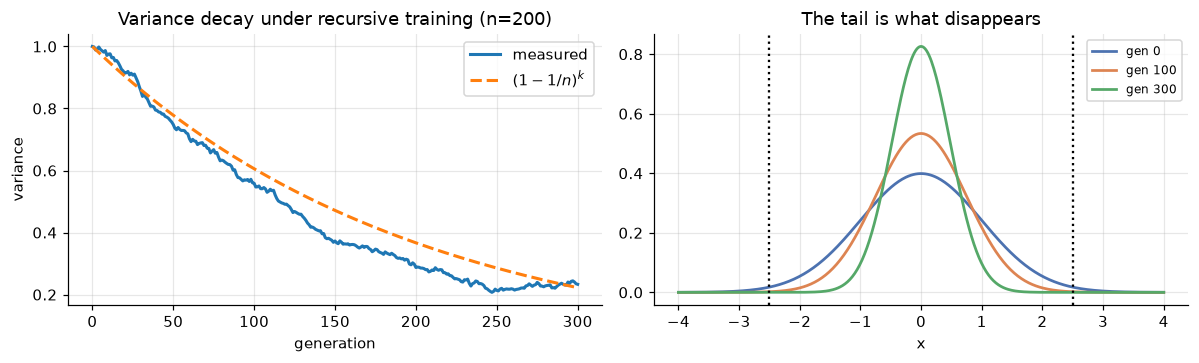

200-CHAIN PILOT, CENTRED GAUSSIAN PROXY: tails use the mean within-chain variance over THESE 200 chains and zero mean.
These are not mixture-tail probabilities or typical-chain measurements. The 5,000-chain comparison two cells
down measures its own mean within-chain variance, and its proxy column is a different number from this one.
P(|x| > 2.5) at generation 0 is 1.2419e-02 — about a 1-in-80 event.
 generation      std      mean    P(|x|>2.5)     vs gen 0
          0   1.0000   +0.0000     1.242e-02      1.0000x
         25   0.9526   +0.0211     8.683e-03      0.6991x
         50   0.8651   +0.0285     3.855e-03      0.3104x
        100   0.7477   -0.0174     8.265e-04      0.0665x
        200   0.5361   -0.0225     3.107e-06      0.0003x
        300   0.4829   -0.0208     2.255e-07      0.0000x

Over 300 generations the standard deviation falls by 52% (1.0000 -> 0.4829),
while the centered proxy tail probability falls by a factor of 55072 (4.7 orders of magnitude).
That proxy was b

In [15]:
NGEN, NSAMP = 300, 200
mu, var = collapse_chain(NSAMP, NGEN, reps=200)
g = np.arange(NGEN + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(g, var.mean(axis=0), lw=2, label="measured")
ax[0].plot(g, (1 - 1/NSAMP)**g, "--", lw=2, label=r"$(1-1/n)^k$")
ax[0].set_xlabel("generation"); ax[0].set_ylabel("variance"); ax[0].legend()
ax[0].set_title(f"Variance decay under recursive training (n={NSAMP})")

thr = 2.5
for k, c in ((0, "#4C72B0"), (100, "#DD8452"), (NGEN, "#55A868")):
    s = np.sqrt(var[:, k].mean())
    xs = np.linspace(-4, 4, 400)
    ax[1].plot(xs, np.exp(-(xs)**2/(2*s**2))/np.sqrt(2*np.pi*s**2), c=c, lw=1.8, label=f"gen {k}")
ax[1].axvline(thr, ls=":", c="k"); ax[1].axvline(-thr, ls=":", c="k")
ax[1].set_title("The tail is what disappears"); ax[1].set_xlabel("x"); ax[1].legend(fontsize=8)
plt.show()

from math import erfc, sqrt
p_base = erfc(thr / sqrt(2))
print("200-CHAIN PILOT, CENTRED GAUSSIAN PROXY: tails use the mean within-chain variance over THESE 200 chains and zero mean.")
print("These are not mixture-tail probabilities or typical-chain measurements. The 5,000-chain comparison two cells")
print("down measures its own mean within-chain variance, and its proxy column is a different number from this one.")
print(f"P(|x| > {thr}) at generation 0 is {p_base:.4e} — about a 1-in-{int(1/p_base)} event.")
print(f"{'generation':>11} {'std':>8} {'mean':>9} {'P(|x|>2.5)':>13} {'vs gen 0':>12}")
p0 = None
for k in (0, 25, 50, 100, 200, NGEN):
    s = np.sqrt(var[:, k].mean()); m = mu[:, k].mean()
    p = erfc(thr / (s * sqrt(2)))
    if p0 is None: p0 = p
    print(f"{k:>11} {s:>8.4f} {m:>+9.4f} {p:>13.3e} {p/p0:>11.4f}x")

s_end = np.sqrt(var[:, NGEN].mean()); p_end = erfc(thr / (s_end * sqrt(2)))
shrink = p0 / p_end
print()
print(f"Over {NGEN} generations the standard deviation falls by {(1-s_end)*100:.0f}% "
      f"(1.0000 -> {s_end:.4f}),")
print(f"while the centered proxy tail probability falls by a factor of {shrink:.0f}"
      f" ({np.log10(shrink):.1f} orders of magnitude).")
print(f"That proxy was built from the pilot's mean within-chain variance at generation {NGEN}: {s_end**2:.4f} over 200 chains.")
print()
print("This proxy illustrates sensitivity of Gaussian tails to narrowing variance.")
print("Actual fitted means drift; the mixture tail requires each chain's own mean and variance.")
print("The variance itself deteriorates: we have not shown that average-case metrics stay healthy.")

In [16]:
# The identity that fences the proxy. Conditional on generation k, the next fitted mean has variance
# v_k/n and the next fitted variance has expectation v_k(1-1/n), so
#     E[v_{k+1}] + Var(mu_{k+1}) = E[v_k](1-1/n) + Var(mu_k) + E[v_k]/n = E[v_k] + Var(mu_k) = v_0.
# Within-chain variance plus between-chain variance is conserved — in expectation. After 300
# generations v_k is spread over orders of magnitude across chains (log v_k has a standard deviation
# of about sqrt(2k/n) = 1.7), so 200 chains are far too few to estimate Var(mu_k) or E[v_k] to a few
# percent. This check therefore runs its own 5,000-chain simulation (own seed; the 200-chain run
# above is untouched, so every number already printed stands).
mu_c, var_c = collapse_chain(NSAMP, NGEN, reps=5000, seed=1)
print(f"Conservation check, n={NSAMP}, {mu_c.shape[0]:,} chains: E[v_k] + Var(mu_k) should stay at v_0 = 1")
print(f"{'gen':>5} {'E[v_k]':>9} {'(1-1/n)^k':>10} {'Var(mu_k)':>10} {'sum':>8} {'boot SE':>8}")
sums, boot_se = [], []
_idx = np.random.default_rng(7).integers(0, mu_c.shape[0], size=(200, mu_c.shape[0]))   # 200 resamples of the 5,000 chains
for k in (0, 25, 50, 100, 200, NGEN):
    ev = var_c[:, k].mean(); vm = mu_c[:, k].var()
    bs = np.array([var_c[i, k].mean() + mu_c[i, k].var() for i in _idx])
    sums.append(ev + vm); boot_se.append(bs.std(ddof=1))
    print(f"{k:>5} {ev:>9.4f} {(1-1/NSAMP)**k:>10.4f} {vm:>10.4f} {ev+vm:>8.4f} {bs.std(ddof=1):>8.4f}")
print(f"The sum at generation {NGEN} is {sums[-1]:.4f} against the theoretical 1.0000: a finite-ensemble deviation of")
print(f"{1-sums[-1]:.4f}, {(1-sums[-1])/boot_se[-1]:.1f} bootstrap standard errors, from averaging a within-chain variance that is")
print(f"spread over orders of magnitude across chains (sd of log v_k ~ sqrt(2k/n) = {np.sqrt(2*NGEN/NSAMP):.2f}) with 5,000 of them.")
print()
mu, var = mu_c, var_c       # the three-tail table below uses the same 5,000 chains

# Three different tails at |x| > 2.5, and they are not the same number:
#   proxy    : centred Gaussian with the MEAN within-chain variance (what the table above printed)
#   median   : the median over chains of each chain's own two-sided tail, at its own mean and variance
#   mixture  : the average over chains of that per-chain tail — the tail of a point drawn from a
#              randomly chosen chain
def two_sided_tail(m, s, thr):
    return 0.5 * erfc((thr - m) / (s * sqrt(2))) + 0.5 * erfc((thr + m) / (s * sqrt(2)))

print(f"P(|x| > {thr}) three ways  (proxy: centred Gaussian with the mean within-chain variance measured on these 5,000 chains)")
print(f"{'gen':>5} {'proxy':>11} {'median chain':>13} {'mixture':>11} {'boot SE':>9} {'mixture vs gen 0':>17}")
mix0 = None
for k in (0, 25, 50, 100, 200, NGEN):
    proxy = erfc(thr / (np.sqrt(var[:, k].mean()) * sqrt(2)))
    per_chain = np.array([two_sided_tail(mu[i, k], np.sqrt(var[i, k]), thr) for i in range(mu.shape[0])])
    mixture = per_chain.mean()
    mix_se = np.array([per_chain[i].mean() for i in _idx]).std(ddof=1)     # bootstrap over chains, same 200 resamples
    if mix0 is None: mix0 = mixture
    print(f"{k:>5} {proxy:>11.3e} {np.median(per_chain):>13.3e} {mixture:>11.3e} {mix_se:>9.1e} {mixture/mix0:>16.3f}x")
print()
# Three variances, three proxies. The proxy column above is built from E[v_k] MEASURED on these 5,000 chains;
# the pilot built its own from 200 chains; the identity gives (1-1/n)^k. They are different numbers because the
# tail is a steep nonlinear function of a mean that is itself spread over orders of magnitude across chains.
print(f"The proxy at generation {NGEN} depends on which variance it is built from:")
for name, v in ((f"identity (1-1/n)^{NGEN}", (1 - 1/NSAMP)**NGEN),
                (f"5,000-chain mean within-chain variance", var[:, NGEN].mean()),
                (f"200-chain pilot mean within-chain variance", s_end**2)):
    _t = erfc(thr / (np.sqrt(v) * sqrt(2)))
    print(f"  {name:>44}: {v:.4f} -> P(|x|>{thr}) = {_t:.3e}, a factor of {p_base/_t:,.0f} below generation 0")
print(f"The pilot's factor ({shrink:,.0f}) and this run's ({p_base/erfc(thr/(np.sqrt(var[:, NGEN].mean())*sqrt(2))):,.0f}) are both centred-proxy numbers;")
print("neither is the identity's, and none of the three is the median chain's or the mixture's.")
print()
proxy_end = erfc(thr / (np.sqrt(var[:, NGEN].mean()) * sqrt(2)))
per_end = np.array([two_sided_tail(mu[i, NGEN], np.sqrt(var[i, NGEN]), thr) for i in range(mu.shape[0])])
if max(abs(s - 1.0) for s in sums) < 0.05 and per_end.mean() > 10 * proxy_end:
    print("Within-chain plus between-chain variance stays at 1 to within sampling error: individual")
    print("chains narrow, their means wander, and a point drawn from a random chain keeps the original")
    print("variance. The mixture tail here is orders of magnitude fatter than the centred proxy's — and heavier than the")
    print("source's at this threshold — NOT because equal variance implies it: with Gaussian-distributed means and equal")
    print("component variances the mixture IS that Gaussian, and 0.5 N(-1, 0.01) + 0.5 N(1, 0.01) has variance 1.01 and")
    print("a far LIGHTER tail than N(0, 1.01) at |x| > 2.5. It is heavier here because the fitted means are not Gaussian-")
    print("distributed and the within-chain variances are unequal, spread over orders of magnitude — which is what this")
    print("table measured. The proxy's collapse factor describes ONE centred model, not the ensemble.")
    print("Both facts are real: a single model's tail can be gone while the ensemble looks unchanged,")
    print("which is why you instrument tail coverage AND location drift per model, not an average.")
else:
    print("Unexpected: the conservation sum or the mixture/proxy ordering is off — inspect before quoting.")
print()
print("Scope fence: this Gaussian recursion is a MECHANISM — the MLE variance bias compounded — not a")
print("model of model collapse. Shumailov-style collapse also moves mass, drops modes and depends on the")
print("fitting class. None of that is in this cell.")

Conservation check, n=200, 5,000 chains: E[v_k] + Var(mu_k) should stay at v_0 = 1
  gen    E[v_k]  (1-1/n)^k  Var(mu_k)      sum  boot SE
    0    1.0000     1.0000     0.0000   1.0000   0.0000
   25    0.8731     0.8822     0.1179   0.9910   0.0076
   50    0.7714     0.7783     0.2199   0.9913   0.0112
  100    0.6000     0.6058     0.3888   0.9889   0.0156
  200    0.3513     0.3670     0.6340   0.9853   0.0229


  300    0.2030     0.2223     0.7565   0.9595   0.0245
The sum at generation 300 is 0.9595 against the theoretical 1.0000: a finite-ensemble deviation of
0.0405, 1.7 bootstrap standard errors, from averaging a within-chain variance that is
spread over orders of magnitude across chains (sd of log v_k ~ sqrt(2k/n) = 1.73) with 5,000 of them.

P(|x| > 2.5) three ways  (proxy: centred Gaussian with the mean within-chain variance measured on these 5,000 chains)
  gen       proxy  median chain     mixture   boot SE  mixture vs gen 0
    0   1.242e-02     1.242e-02   1.242e-02   1.7e-18            1.000x
   25   7.462e-03     6.913e-03   1.818e-02   4.1e-04            1.464x
   50   4.422e-03     3.521e-03   2.122e-02   6.3e-04            1.709x
  100   1.249e-03     4.938e-04   2.382e-02   8.3e-04            1.918x
  200   2.467e-05     9.285e-08   2.463e-02   1.2e-03            1.983x
  300   2.881e-08     3.336e-17   2.294e-02   1.4e-03            1.847x

The proxy at generation 300 depen

---
## What every week was optimising, in one table

| Week | System | The quantity it was actually minimising |
|---|---|---|
| [W13](https://artifocial.com/blog/energy-based-world-models-2026-mar-25) | World models / JEPA | prediction surprise in a compressed latent — an information bottleneck by construction |
| [W14](https://artifocial.com/blog/gaussian-splatting-explained-2026-apr-03) | 3D Gaussian splatting | rate vs distortion: how many primitives buy how much fidelity (§4) |
| [W15](https://artifocial.com/blog/post-transformer-architectures-2026-apr-09) | Post-transformer architectures | cross-entropy per parameter — the objective never changed, only the mixer |
| [W16](https://artifocial.com/blog/4d-gaussian-splatting-explained-2026-apr-17) | 4D / temporal | conditional entropy $H(\text{frame}_t \mid \text{frame}_{t-1})$ |
| [W28](https://artifocial.com/blog/attention-is-a-kernel-2026-jul-12) | Attention as a kernel | for the Gaussian-process reading of a *stationary* kernel: an entropy rate set by the log-average of its spectral density (§1). A softmax attention matrix is not such a kernel, and the theorem does not reach it |
| [W29](https://artifocial.com/blog/probabilistic-3d-reconstruction-2026-jul-16) | Diffusion for 3D | a sum of per-step KL divergences (§2) |
| [W32](https://artifocial.com/blog/neuro-symbolic-reasoning-2026-aug-6) | Neuro-symbolic | entropy over consistent worlds, reduced by each constraint |
| [W33](https://artifocial.com/blog/planning-under-uncertainty-2026-aug-16) | Planning under uncertainty | expected free energy = expected surprise, exploration included |
| [W35/36](https://artifocial.com/blog/game-inside-the-network-2026-aug-28) | Game theory | maximum entropy as the minimax-robust choice |
| [W38](https://artifocial.com/blog/frequency-domain-2026-sep-17) | The frequency domain | the spectral density whose log-average fixes a Gaussian process's entropy rate (§1) |

The honest version of the claim this week makes is not "everything is information theory." It is
narrower and more useful: **these systems have objectives that are measurable in bits, the
measurement is often exactly computable, and doing it tells you things the loss curve does not** —
that the spectrum fixes the entropy rate through its geometric mean and not through its Shannon
entropy (§1), that equal ELBO scores can hide different decompositions without proving collapse (§3),
that scalar quantisation has a high-resolution rate penalty (§4), and that a single recursively
trained model can lose its tail while the ensemble of such models conserves the variance in expectation and,
in this run, shows a heavier tail than the source (§6).
These diagnostics do not certify training quality or real-system behaviour.